# Squares in Squares: submission explorer

Pick a submission (default: the newest file in `submissions/`), see which puzzles hold the most score, and draw any packing as an SVG.

Score per puzzle is `L/√n − 1`; lower is better. The top of the table is where more work pays most.

In [1]:
%load_ext autoreload
# pick up edits to squares_viz.py without restarting the kernel
%autoreload 2
import sys, pandas as pd
from IPython.display import SVG, HTML, display
sys.path.insert(0, '.')            # run from analysis/
import squares_viz as sv
%matplotlib inline

SUBMISSION = None                  # e.g. '../submissions/submission_20261025_190950.csv'; None = newest

In [2]:
path, packings = sv.load_submission(SUBMISSION)
df = sv.per_n_table(packings)
print('submission:', path)
print(f'puzzles present: {df.present.sum()}/1000   total score: {df.score.sum():.10f}   grid total: {df.grid_score.sum():.10f}')

submission: /home/anujs/Anuj-Singhal/Projects/Development/kaggle-competitions/competitions/squares-in-squares/submissions/submission_20261025_192324.csv
puzzles present: 1000/1000   total score: 22.2987580136   grid total: 28.9376699166


## Per-n scores, worst first

`gain_vs_grid` is how much that puzzle already beats the grid; `share_of_total` is its slice of the leaderboard score; `tilted_frac` is the fraction of squares that are rotated. The full table is also saved to `analysis/out/per_n_scores.csv`.

In [14]:
import os
os.makedirs(sv.OUT, exist_ok=True)
df.to_csv(os.path.join(sv.OUT, 'per_n_scores.csv'), index=False)
with pd.option_context('display.max_rows', None, 'display.width', 140, 'display.float_format', '{:.6f}'.format):
    display(df[:20])

,n,L,score,grid_score,tilted_frac,present,gain_vs_grid,share_of_total
0,2,2.000000,0.414214,0.414214,0.000000,True,0.000000,0.018576
1,6,3.000000,0.224745,0.224745,0.000000,True,0.000000,0.010079
2,5,2.707107,0.210655,0.341641,0.200000,True,0.130986,0.009447
3,10,3.707107,0.172290,0.264911,0.100000,True,0.092621,0.007726
4,11,3.877084,0.168985,0.206045,0.454545,True,0.037061,0.007578
5,12,4.000000,0.154701,0.154701,0.000000,True,0.000000,0.006938
6,3,2.000000,0.154701,0.154701,0.000000,True,0.000000,0.006938
7,18,4.822876,0.136763,0.178511,0.444444,True,0.041749,0.006133
8,17,4.675530,0.133983,0.212678,0.411765,True,0.078696,0.006009
9,7,3.000000,0.133893,0.133893,0.000000,True,0.000000,0.006005


## Score per puzzle

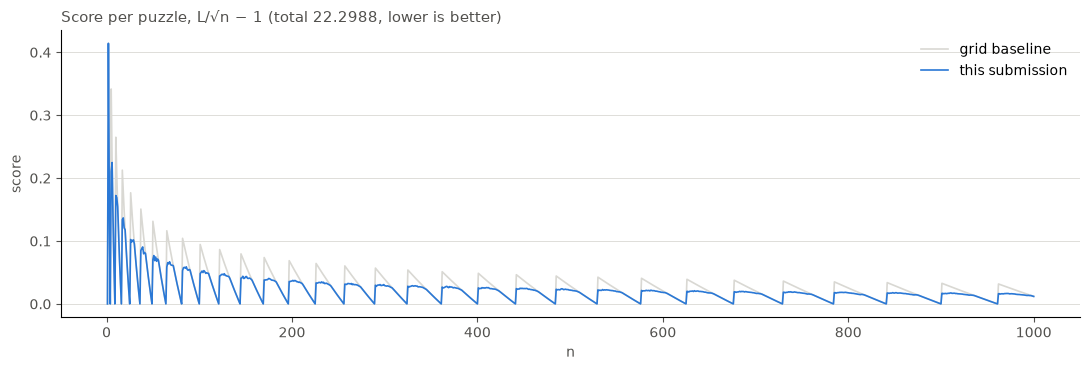

In [4]:
fig = sv.plot_per_n(df)

## Buckets of n

Where the score total lives, and how much of the grid's excess is already gone, in buckets of 50.

,label,total,mean,gain
bucket,,,,
0,1–50,4.166276,0.083326,0.826443
1,51–100,2.134910,0.042698,0.544928
2,101–150,1.726874,0.034537,0.600613
3,151–200,1.366272,0.027325,0.389670
4,201–250,1.303814,0.026076,0.338909
5,251–300,1.094181,0.021884,0.432716
6,301–350,1.071058,0.021421,0.265988
7,351–400,0.815354,0.016307,0.235653
8,401–450,0.954699,0.019094,0.396006


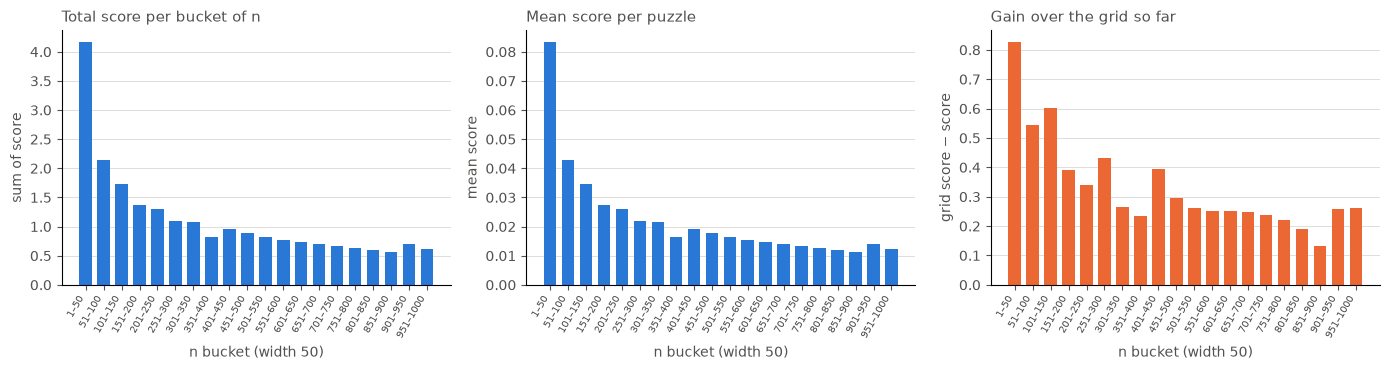

In [5]:
fig, buckets = sv.plot_buckets(df, width=50)
buckets[['label', 'total', 'mean', 'gain']]

## Look at a packing

`sv.svg_packing(n, packings)` draws puzzle n with random solid colours and prints the side `L` on the bounding box. Files are saved as `analysis/out/n_XXXX.svg`.

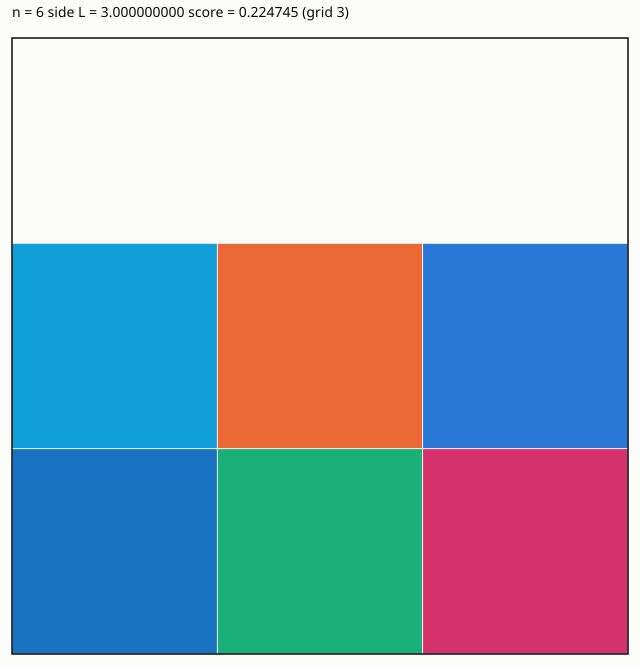

In [6]:
N = int(df.iloc[0].n)             # change to any n; default: the worst-scoring puzzle
N = 6
SVG(sv.svg_packing(N, packings))

In [7]:
# the four worst puzzles side by side
HTML(''.join(f'<div style="display:inline-block;width:48%">{sv.svg_packing(int(n), packings, size=420)}</div>' for n in df.n.head(4)))

## Headroom: how far are we from the best team, per puzzle?

`headroom = our score − the best score any team holds for that n` (from the host's per-puzzle leaderboard), sorted largest first. Zero means we are level with the best known packing, so only a new record would help there.

To refresh the leaderboard: open Kaggle's *Squares in Squares - Per-Puzzle Leaderboard* notebook, download it (File → Download, with outputs), then run the import cell below. Kaggle refreshes it about once a day.

This is an upper bound on what is reachable right now, since it is what other teams have already achieved.

In [8]:
import importlib; sv = importlib.reload(sv)   # make sure we have the latest squares_viz.py
# sv.import_leaderboard_ipynb()        # uncomment after downloading a fresh copy to ~/Downloads (or pass its path)
hd = sv.headroom_table(df)
total = hd.headroom.clip(lower=0).sum()
print(f'we are behind the best team on {(hd.headroom > 1e-7).sum()} puzzles; total headroom {total:.6f} (our score {df.score.sum():.6f} -> {df.score.sum() - total:.6f} if we matched all of them)')

we are behind the best team on 341 puzzles; total headroom 0.130304 (our score 22.298758 -> 22.168454 if we matched all of them)


In [13]:
cols = ['n', 'L', 'best_L', 'headroom_L', 'score', 'best_score', 'headroom', 'headroom_share', 'team', 'date']
with pd.option_context('display.max_rows', None, 'display.width', 200, 'display.float_format', '{:.6f}'.format):
    display(hd[cols][:20])

,n,L,best_L,headroom_L,score,best_score,headroom,headroom_share,team,date
0,335,18.822876,18.794904,0.027971,0.028404,0.026875,0.001528,0.011728,404 Space Not Found,2026-10-23 22:53:00 UTC
1,454,21.823103,21.794447,0.028656,0.024209,0.022864,0.001345,0.010321,404 Space Not Found,2026-10-24 13:03:04 UTC
2,412,20.822876,20.798166,0.024710,0.025869,0.024652,0.001217,0.009343,Cats and boxes 😼,2026-10-24 18:52:10 UTC
3,373,19.823062,19.800020,0.023042,0.026399,0.025206,0.001193,0.009156,Cats and boxes 😼,2026-10-24 21:27:07 UTC
4,299,17.822876,17.802719,0.020157,0.030724,0.029558,0.001166,0.008946,Amin,2026-10-23 00:15:35 UTC
5,803,28.827585,28.796006,0.031579,0.017303,0.016189,0.001114,0.008552,Umong Sain,2026-10-24 17:36:52 UTC
6,498,22.823387,22.798814,0.024573,0.022740,0.021639,0.001101,0.008451,404 Space Not Found,2026-10-24 03:47:10 UTC
7,544,23.824485,23.799034,0.025451,0.021466,0.020375,0.001091,0.008374,Umong Sain,2026-10-24 17:36:52 UTC
8,861,29.828047,29.796131,0.031916,0.016537,0.015449,0.001088,0.008347,Umong Sain,2026-10-24 17:36:52 UTC
9,591,24.819591,24.793812,0.025778,0.020942,0.019881,0.001060,0.008138,404 Space Not Found,2026-10-24 03:47:10 UTC


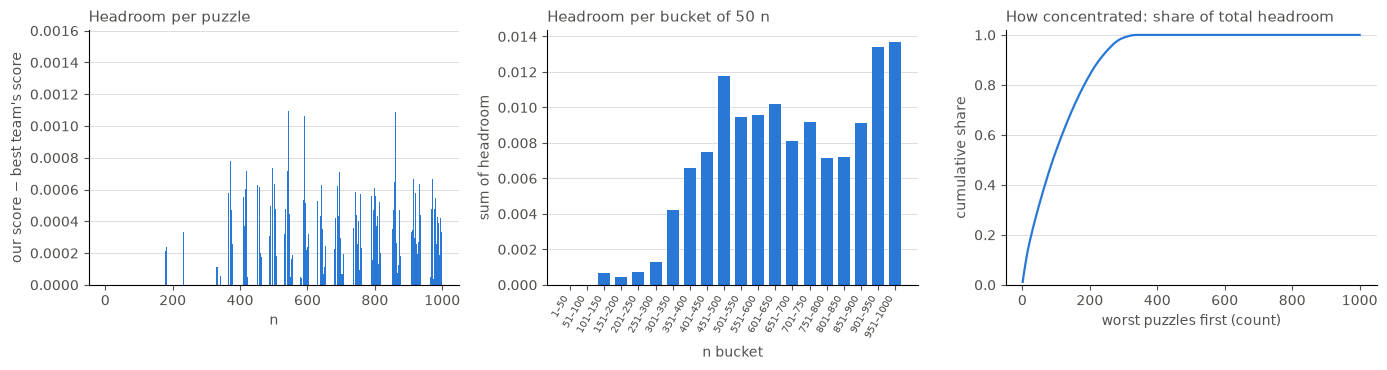

In [10]:
fig = sv.plot_headroom(hd, width=50)

In [15]:
# headroom by band of n, and who holds the puzzles we are behind on
band = pd.cut(hd.n, [0, 100, 200, 324, 500, 750, 1000])
print(hd.groupby(band, observed=True).agg(puzzles=('n', 'size'), behind=('headroom', lambda x: (x > 1e-7).sum()), headroom=('headroom', lambda x: x.clip(lower=0).sum())).to_string(float_format='{:.4f}'.format))
print()
print(hd[hd.headroom > 1e-7].groupby('team').headroom.agg(['count', 'sum']).sort_values('sum', ascending=False).head(10).to_string(float_format='{:.4f}'.format))

             puzzles  behind  headroom
n                                     
(0, 100]         100       0    0.0000
(100, 200]       100       5    0.0011
(200, 324]       124       9    0.0024
(324, 500]       176      72    0.0297
(500, 750]       250     119    0.0465
(750, 1000]      250     136    0.0506

                     count    sum
team                             
404 Space Not Found     82 0.0382
Umong Sain              70 0.0320
Cats and boxes 😼        52 0.0184
Subramanya N            57 0.0155
Amin                    31 0.0111
shyjin                  18 0.0078
Pardheev Krishna         4 0.0016
Maximiliano              3 0.0012
odin free                4 0.0012
Kirill Khoruzhii         4 0.0008
